In [142]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


URL = "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD"
# on a déja le fichier en local
local_file = "data/fremont.csv"
from pathlib import Path

if Path(local_file).exists():
    print(f"le fichier {local_file} est déjà là")
else:
    print(f"allons chercher le fichier {local_file}")

    import requests
    req = requests.get(URL)
    print(req.status_code)

    with open(local_file, 'w') as writer:
        writer.write(req.text)


# version naïve
data = pd.read_csv(local_file)
data.shape

data.head()

le fichier data/fremont.csv est déjà là


,Date,Fremont Bridge Total,Fremont Bridge East Sidewalk,Fremont Bridge West Sidewalk
0,08/01/2022 12:00:00 AM,23.0,7.0,16.0
1,08/01/2022 01:00:00 AM,12.0,5.0,7.0
2,08/01/2022 02:00:00 AM,3.0,0.0,3.0
3,08/01/2022 03:00:00 AM,5.0,2.0,3.0
4,08/01/2022 04:00:00 AM,10.0,2.0,8.0


In [143]:
#Doublons
print(data.shape)
data.drop_duplicates(inplace=True)
print(data.shape) 

(175200, 4)
(87600, 4)


In [144]:
#Echauffement DatetimeIndex
sample_dates = pd.to_datetime([
    "2024-01-15 08:00:00",
    "2024-01-20 17:30:00",
    "2024-02-03 12:00:00",])

#1 
print(type(sample_dates))

#sample_dates est de type pandas.DatetimeIndex.

#2

print(sample_dates.date, sample_dates.time, sample_dates.dayofweek)

#Cela renvoie une liste contenant les dates (resp. l'heure, le jour de la semaine sous forme numérique : lundi=0, mardi=1, etc.).

#3
print(sample_dates[sample_dates>pd.to_datetime("2024-01-20 00:00:00")])
#On restreint sample_dates aux éléments ultérieurs au 20 janvier 2024, à minuit.
#N.B. : on peut appliquer pd.to_datetime à un string.

#4
s=sample_dates[pd.to_datetime("2024-01-01 00:00:00")<=sample_dates]
print(s[sample_dates<=pd.to_datetime("2024-01-31 23:59:59")])
#De même qu'en Q3), mais on fait deux restrictions.

<class 'pandas.DatetimeIndex'>
[datetime.date(2024, 1, 15) datetime.date(2024, 1, 20)
 datetime.date(2024, 2, 3)] [datetime.time(8, 0) datetime.time(17, 30) datetime.time(12, 0)] Index([0, 5, 5], dtype='int32')
DatetimeIndex(['2024-01-20 17:30:00', '2024-02-03 12:00:00'], dtype='datetime64[us]', freq=None)
DatetimeIndex(['2024-01-15 08:00:00', '2024-01-20 17:30:00'], dtype='datetime64[us]', freq=None)


In [145]:
#Parser les dates

data.index=pd.to_datetime(data.Date, format="%m/%d/%Y %I:%M:%S %p")
del data["Date"]


In [146]:
#Renommage des colonnes 

data.columns=["Total", "West", "East"]
print(data.head())


                     Total  West  East
Date                                  
2022-08-01 00:00:00   23.0   7.0  16.0
2022-08-01 01:00:00   12.0   5.0   7.0
2022-08-01 02:00:00    3.0   0.0   3.0
2022-08-01 03:00:00    5.0   2.0   3.0
2022-08-01 04:00:00   10.0   2.0   8.0


In [147]:
#Données manquantes et extension types

#1

print("Nombre de lignes avec valeurs manquantes") 
print(data[data.isna().any(axis=1)].shape)



Nombre de lignes avec valeurs manquantes
(14, 3)


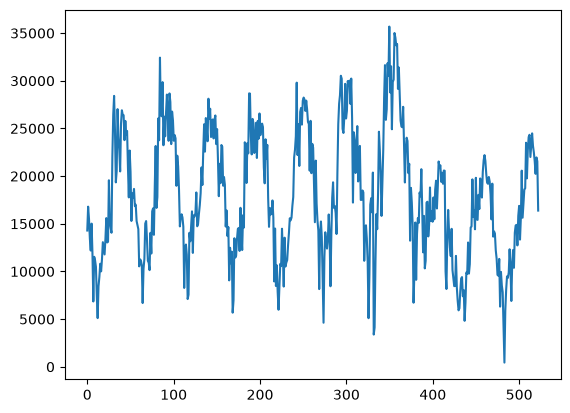

0.9989053092501369


In [148]:
#Changer la fréquence temporelle

#1
plt.figure(1)
newsample=(data['Total'].resample('1W')).sum()
#On "group by" le total des données par semaine, et on somme à chaque fois sur une semaine

plt.plot(np.linspace(0,len(newsample), num=len(newsample)),newsample)
#On trace avec en abscisse, autant de semaines que newsample a d'éléments

plt.show()

#2

print((len(data['Total'])/len(newsample))/(7*24)) 
#On voit si le rapport entre les tailles des tableaux avant et après agrégation sont proches de 7*24 : la division du rapport des deux tailles par 7*24 est bien très proche de 1.




In [ ]:
#Découpage temporel

